In [ ]:
!pip install -q kagglehub scikit-learn opencv-python-headless
import tensorflow as tf
import numpy as np
import cv2
import kagglehub
import sklearn

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("NumPy version:", np.__version__)
print("OpenCV version:", cv2.__version__)

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
NumPy version: 2.1.3
OpenCV version: 5.0.0


In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "greatgamedota/dfdc-part-34"
)

print("Dataset downloaded to:")
print(dataset_path)

100%|██████████| 147M/147M [00:08<00:00, 18.1MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/greatgamedota/dfdc-part-34/versions/1


In [ ]:
import os

print("Main dataset files:")
print(os.listdir(dataset_path))

images_path = os.path.join(dataset_path, "images")

print("\nImages folder exists:", os.path.exists(images_path))

if os.path.exists(images_path):
    items = os.listdir(images_path)
    print("Number of items:", len(items))
    print("First 10 items:", items[:10])

Main dataset files:
['images']

Images folder exists: True
Number of items: 2659
First 10 items: ['afkfjviffj', 'irlisfshaq', 'pyzuldgecn', 'aoszdeayes', 'livxzjtmmh', 'vvrntobole', 'ioruwzdrhe', 'qvudvfntjy', 'fxlbozuoas', 'vwgrapvvsc']


In [ ]:
import pandas as pd

metadata_path = os.path.join(
    images_path,
    "metadata34.csv"
)

metadata = pd.read_csv(metadata_path)

print(metadata.head())
print("\nColumns:", metadata.columns.tolist())
print("\nLabel counts:")
print(metadata["label"].value_counts())
print("\nTotal records:", len(metadata))

         filename label  split        original
0  zhmjtavtpn.mp4  FAKE  train  ejnrxekehh.mp4
1  dazellwbsl.mp4  FAKE  train  xuxkfhqjiu.mp4
2  elwdztqnot.mp4  FAKE  train  xlyxbyhjsq.mp4
3  fiedwlcwyn.mp4  FAKE  train  skhnvzyukn.mp4
4  svbcewtjvh.mp4  FAKE  train  arrpqqfiah.mp4

Columns: ['filename', 'label', 'split', 'original']

Label counts:
label
FAKE    2242
REAL     416
Name: count, dtype: int64

Total records: 2658


In [ ]:
metadata["filename"] = metadata["filename"].str.replace(
    ".mp4",
    "",
    regex=False
)

metadata["original"] = metadata["original"].fillna("").str.replace(
    ".mp4",
    "",
    regex=False
)

available_folders = {
    name
    for name in os.listdir(images_path)
    if os.path.isdir(os.path.join(images_path, name))
}

metadata = metadata[
    metadata["filename"].isin(available_folders)
].copy()

real_metadata = metadata[
    metadata["label"] == "REAL"
].copy()

fake_metadata = metadata[
    metadata["label"] == "FAKE"
].copy()

print("Available real folders:", len(real_metadata))
print("Available fake folders:", len(fake_metadata))
print("\nExample real folders:")
print(real_metadata["filename"].head())
print("\nExample fake folders:")
print(fake_metadata["filename"].head())

Available real folders: 416
Available fake folders: 2242

Example real folders:
42    mulebpmvzo
43    lbqfkivkqr
57    ndpytliklg
62    nrherwjzle
74    ntttcqmyjm
Name: filename, dtype: object

Example fake folders:
0    zhmjtavtpn
1    dazellwbsl
2    elwdztqnot
3    fiedwlcwyn
4    svbcewtjvh
Name: filename, dtype: object


In [ ]:
fake_with_real = fake_metadata[
    fake_metadata["original"].isin(
        real_metadata["filename"]
    )
].copy()

selected_fakes = (
    fake_with_real
    .sample(frac=1, random_state=42)
    .drop_duplicates(subset="original")
)

video_pairs = selected_fakes[
    ["original", "filename"]
].rename(
    columns={
        "original": "real_folder",
        "filename": "fake_folder",
    }
).reset_index(drop=True)

print(video_pairs.head())
print("\nNumber of balanced video pairs:", len(video_pairs))
print("Real videos:", video_pairs["real_folder"].nunique())
print("Fake videos:", video_pairs["fake_folder"].nunique())

  real_folder fake_folder
0  stixwmpppk  xmjrjpauyh
1  buznnntmnf  yndvuscznt
2  sectcrwsak  lohvbaadme
3  shjpuxwkos  enybsjbxeu
4  lcdguqhxtb  fhodnvppkz

Number of balanced video pairs: 416
Real videos: 416
Fake videos: 416


In [ ]:
from sklearn.model_selection import train_test_split

train_pairs, remaining_pairs = train_test_split(
    video_pairs,
    test_size=0.30,
    random_state=42,
)

validation_pairs, test_pairs = train_test_split(
    remaining_pairs,
    test_size=0.50,
    random_state=42,
)

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(validation_pairs))
print("Testing pairs:", len(test_pairs))

print(
    "\nTotal:",
    len(train_pairs)
    + len(validation_pairs)
    + len(test_pairs)
)

Training pairs: 291
Validation pairs: 62
Testing pairs: 63

Total: 416


In [ ]:
def create_image_dataframe(pairs):
    records = []

    for _, pair in pairs.iterrows():
        real_folder = pair["real_folder"]
        fake_folder = pair["fake_folder"]

        real_path = os.path.join(
            images_path,
            real_folder,
        )

        fake_path = os.path.join(
            images_path,
            fake_folder,
        )

        real_frames = {
            name
            for name in os.listdir(real_path)
            if name.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        }

        fake_frames = {
            name
            for name in os.listdir(fake_path)
            if name.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        }

        common_frames = sorted(
            real_frames.intersection(fake_frames)
        )

        for frame_name in common_frames:
            records.append({
                "filepath": os.path.join(
                    real_path,
                    frame_name,
                ),
                "label": 0,
                "class_name": "REAL",
            })

            records.append({
                "filepath": os.path.join(
                    fake_path,
                    frame_name,
                ),
                "label": 1,
                "class_name": "FAKE",
            })

    return pd.DataFrame(records)


train_data = create_image_dataframe(train_pairs)
validation_data = create_image_dataframe(validation_pairs)
test_data = create_image_dataframe(test_pairs)

print("Training images:", len(train_data))
print(train_data["class_name"].value_counts())

print("\nValidation images:", len(validation_data))
print(validation_data["class_name"].value_counts())

print("\nTesting images:", len(test_data))
print(test_data["class_name"].value_counts())

Training images: 5820
class_name
REAL    2910
FAKE    2910
Name: count, dtype: int64

Validation images: 1240
class_name
REAL    620
FAKE    620
Name: count, dtype: int64

Testing images: 1260
class_name
REAL    630
FAKE    630
Name: count, dtype: int64


In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_dataset_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        antialias=True,
    )

    image = tf.cast(image, tf.float32)
    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(dataframe, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["filepath"].values,
            dataframe["label"].values,
        )
    )

    dataset = dataset.map(
        load_dataset_image,
        num_parallel_calls=AUTOTUNE,
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = make_dataset(
    train_data,
    training=True,
)

validation_dataset = make_dataset(
    validation_data,
)

test_dataset = make_dataset(
    test_data,
)

sample_images, sample_labels = next(
    iter(train_dataset)
)

print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Minimum pixel value:", tf.reduce_min(sample_images).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


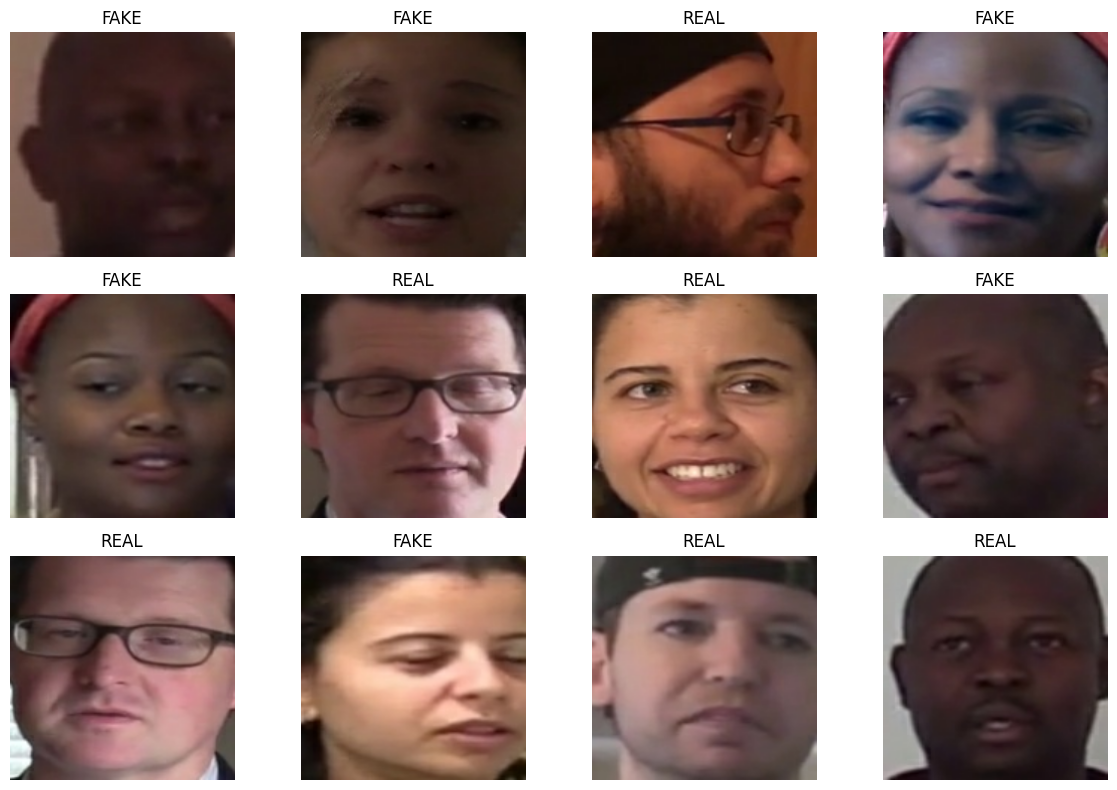

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for index in range(12):
    plt.subplot(3, 4, index + 1)

    image = sample_images[index].numpy().astype(
        np.uint8
    )

    label = int(sample_labels[index].numpy())
    class_name = "FAKE" if label == 1 else "REAL"

    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.05),
        layers.RandomContrast(0.05),
    ],
    name="data_augmentation",
)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
)

base_model.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image",
)

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="deepfake_probability",
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Detect_Now_EfficientNetB0",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "Detect_Now_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deepfake_probability (Dense)    │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
import os

project_folder = "/content/Detect_Now_Model"

os.makedirs(
    project_folder,
    exist_ok=True,
)

print("Model files will be saved temporarily in:")
print(project_folder)

Model files will be saved temporarily in:
/content/Detect_Now_Model


In [ ]:
checkpoint_path = os.path.join(
    project_folder,
    "stage1_best.keras",
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(
            project_folder,
            "stage1_training.csv",
        )
    ),
]

stage1_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=callbacks,
)

Epoch 1/15
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.4960 - auc: 0.4825 - loss: 0.7279 - precision: 0.5019 - recall: 0.6111
Epoch 1: val_auc improved from None to 0.53781, saving model to /content/Detect_Now_Model/stage1_best.keras

Epoch 1: finished saving model to /content/Detect_Now_Model/stage1_best.keras
182/182 ━━━━━━━━━━━━━━━━━━━━ 48s 127ms/step - accuracy: 0.5015 - auc: 0.4964 - loss: 0.7212 - precision: 0.5014 - recall: 0.5378 - val_accuracy: 0.5169 - val_auc: 0.5378 - val_loss: 0.6914 - val_precision: 0.5168 - val_recall: 0.5210 - learning_rate: 1.0000e-04
Epoch 2/15
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.5299 - auc: 0.5349 - loss: 0.7009 - precision: 0.5410 - recall: 0.5608
Epoch 2: val_auc improved from 0.53781 to 0.57740, saving model to /content/Detect_Now_Model/stage1_best.keras

Epoch 2: finished saving model to /content/Detect_Now_Model/stage1_best.keras
182/182 ━━━━━━━━━━━━━━━━━━━━ 31s 110ms/step - accuracy: 0.5239 - auc: 0.5307 - loss: 

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization,
    ):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

stage2_path = os.path.join(
    project_folder,
    "detect_now_efficientnetb0.keras",
)

stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage2_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=0.0000001,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(
            project_folder,
            "stage2_training.csv",
        )
    ),
]

stage2_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=stage2_callbacks,
)

Epoch 1/15
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.6223 - auc: 0.6802 - loss: 0.6426 - precision: 0.6165 - recall: 0.6143
Epoch 1: val_auc improved from None to 0.73982, saving model to /content/Detect_Now_Model/detect_now_efficientnetb0.keras

Epoch 1: finished saving model to /content/Detect_Now_Model/detect_now_efficientnetb0.keras
182/182 ━━━━━━━━━━━━━━━━━━━━ 51s 131ms/step - accuracy: 0.6285 - auc: 0.6850 - loss: 0.6399 - precision: 0.6279 - recall: 0.6309 - val_accuracy: 0.6710 - val_auc: 0.7398 - val_loss: 0.6276 - val_precision: 0.7218 - val_recall: 0.5565 - learning_rate: 1.0000e-05
Epoch 2/15
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.6410 - auc: 0.7049 - loss: 0.6257 - precision: 0.6352 - recall: 0.6686
Epoch 2: val_auc improved from 0.73982 to 0.75454, saving model to /content/Detect_Now_Model/detect_now_efficientnetb0.keras

Epoch 2: finished saving model to /content/Detect_Now_Model/detect_now_efficientnetb0.keras
182/182 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

best_model = tf.keras.models.load_model(
    stage2_path
)

test_probabilities = best_model.predict(
    test_dataset
).reshape(-1)

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

test_labels = test_data["label"].values

accuracy = accuracy_score(
    test_labels,
    test_predictions,
)

precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0,
)

recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0,
)

f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0,
)

auc = roc_auc_score(
    test_labels,
    test_probabilities,
)

matrix = confusion_matrix(
    test_labels,
    test_predictions,
)

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print(f"Test AUC:       {auc:.4f}")

print("\nConfusion Matrix:")
print(matrix)

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["REAL", "FAKE"],
        digits=4,
    )
)

40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 161ms/step
Test Accuracy:  0.7667
Test Precision: 0.8256
Test Recall:    0.6762
Test F1-score:  0.7435
Test AUC:       0.8709

Confusion Matrix:
[[540  90]
 [204 426]]

Classification Report:
              precision    recall  f1-score   support

        REAL     0.7258    0.8571    0.7860       630
        FAKE     0.8256    0.6762    0.7435       630

    accuracy                         0.7667      1260
   macro avg     0.7757    0.7667    0.7647      1260
weighted avg     0.7757    0.7667    0.7647      1260



In [ ]:
from google.colab import files

files.download(
    "/content/Detect_Now_Model/"
    "detect_now_efficientnetb0.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import numpy as np
import tensorflow as tf

uploaded = files.upload()

uploaded_filename = next(
    iter(uploaded)
)

test_image = tf.keras.utils.load_img(
    uploaded_filename,
    target_size=(224, 224),
)

test_array = tf.keras.utils.img_to_array(
    test_image
)

test_batch = np.expand_dims(
    test_array,
    axis=0,
)

fake_score = float(
    best_model.predict(
        test_batch,
        verbose=0,
    )[0][0]
)

real_score = 1.0 - fake_score

prediction = (
    "DEEPFAKE"
    if fake_score >= 0.5
    else "REAL"
)

print("Prediction:", prediction)
print(f"Real probability: {real_score * 100:.2f}%")
print(f"Deepfake probability: {fake_score * 100:.2f}%")

Saving main photo.jpg to main photo.jpg


NameError: name 'best_model' is not defined

In [ ]:
from google.colab import files
import tensorflow as tf
import numpy as np
import os

model_path = (
    "/content/Detect_Now_Model/"
    "detect_now_efficientnetb0.keras"
)

if not os.path.exists(model_path):
    print(
        "Upload detect_now_efficientnetb0.keras"
    )

    uploaded_model = files.upload()

    model_path = next(
        filename
        for filename in uploaded_model
        if filename.endswith(".keras")
    )

best_model = tf.keras.models.load_model(
    model_path,
    compile=False,
)

image_path = "main photo.jpg"

if not os.path.exists(image_path):
    print("Upload your genuine image")

    uploaded_image = files.upload()

    image_path = next(
        filename
        for filename in uploaded_image
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    )

test_image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224),
)

test_array = tf.keras.utils.img_to_array(
    test_image
)

test_batch = np.expand_dims(
    test_array,
    axis=0,
)

fake_score = float(
    best_model.predict(
        test_batch,
        verbose=0,
    )[0][0]
)

real_score = 1.0 - fake_score

prediction = (
    "DEEPFAKE"
    if fake_score >= 0.5
    else "REAL"
)

print("Prediction:", prediction)
print(
    f"Real probability: "
    f"{real_score * 100:.2f}%"
)
print(
    f"Deepfake probability: "
    f"{fake_score * 100:.2f}%"
)

Upload detect_now_efficientnetb0.keras


Saving main photo.jpg to main photo (1).jpg


StopIteration: 

In [ ]:
from google.colab import files

print(
    "Select detect_now_efficientnetb0.keras "
    "from your Detect now/model folder."
)

uploaded_model = files.upload()


Select detect_now_efficientnetb0.keras from your Detect now/model folder.


KeyboardInterrupt: 

In [ ]:
import glob
import os
import numpy as np
import tensorflow as tf

model_files = glob.glob(
    "/content/*.keras"
)

image_files = (
    glob.glob("/content/*.jpg")
    + glob.glob("/content/*.jpeg")
    + glob.glob("/content/*.png")
)

print("Model files:", model_files)
print("Image files:", image_files)

model_path = model_files[0]

image_path = max(
    image_files,
    key=os.path.getmtime,
)

best_model = tf.keras.models.load_model(
    model_path,
    compile=False,
)

test_image = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224),
)

test_array = tf.keras.utils.img_to_array(
    test_image
)

test_batch = np.expand_dims(
    test_array,
    axis=0,
)

fake_score = float(
    best_model.predict(
        test_batch,
        verbose=0,
    )[0][0]
)

real_score = 1.0 - fake_score

prediction = (
    "DEEPFAKE"
    if fake_score >= 0.5
    else "REAL"
)

print("\nPrediction:", prediction)
print(
    f"Real probability: "
    f"{real_score * 100:.2f}%"
)
print(
    f"Deepfake probability: "
    f"{fake_score * 100:.2f}%"
)

Model files: ['/content/detect_now_efficientnetb0.keras']
Image files: ['/content/main photo.jpg', '/content/main photo (1).jpg']

Prediction: REAL
Real probability: 68.48%
Deepfake probability: 31.52%
